# Agregações de crescimento e receita

Responde à trilha **Crescimento e Receita** do Tech Challenge:
1. Evolução mensal de pedidos, receita e ticket médio.
2. Participação por categoria e por UF.
3. Produtos e sellers com melhor desempenho.

As tabelas agregadas são salvas em `data/processed/` com o prefixo `agg_`, para uso no relatório e na apresentação.

## Bibliotecas

In [1]:
%run ../../src/librarys.ipynb

## Carga da camada processed

In [2]:
orders_enriched = pd.read_csv("../../data/processed/orders_enriched.csv", parse_dates=["order_purchase_timestamp"])
order_items_category = pd.read_csv("../../data/processed/order_items_category.csv", parse_dates=["order_purchase_timestamp"])
sellers = pd.read_csv("../../data/processed/sellers.csv", dtype={"seller_zip_code_prefix": str})
customers = pd.read_csv("../../data/processed/customers.csv", dtype={"customer_zip_code_prefix": str})

## Regras das agregações

Seguem as regras definidas no [relatório de qualidade](../../docs/relatorio-de-qualidade.md):

- **Somente pedidos entregues (`DELIVERED`):** pedidos cancelados, indisponíveis ou em andamento não representam venda realizada.
- **Período de jan/2017 a ago/2018:** os meses fora desse intervalo têm volume muito baixo (início da operação e corte da extração) e criariam quedas artificiais nos gráficos.
- **Receita = preço + frete:** valor total pago pelo cliente (GMV). É o mesmo valor de `order_total`.
- **Ticket médio = receita ÷ número de pedidos.**

In [3]:
pedidos = orders_enriched[
    (orders_enriched["order_status"] == "DELIVERED")
    & (orders_enriched["order_purchase_timestamp"] >= "2017-01-01")
    & (orders_enriched["order_purchase_timestamp"] < "2018-09-01")
]

itens = order_items_category[
    (order_items_category["order_status"] == "DELIVERED")
    & (order_items_category["order_purchase_timestamp"] >= "2017-01-01")
    & (order_items_category["order_purchase_timestamp"] < "2018-09-01")
].copy()
itens["item_total"] = itens["price"] + itens["freight_value"]

print("Pedidos considerados:", len(pedidos), "de", len(orders_enriched))
print("Itens considerados:", len(itens), "de", len(order_items_category))

Pedidos considerados: 96211 de 99441
Itens considerados: 109880 de 112650


## Indicadores gerais do período

Visão consolidada para abrir o relatório. Clientes são contados pelo `customer_unique_id`, que identifica a pessoa (o `customer_id` muda a cada pedido).

In [4]:
clientes = pedidos.merge(customers[["customer_id", "customer_unique_id"]], on="customer_id")

receita_total = pedidos["order_total"].sum()
total_pedidos = pedidos["order_id"].nunique()

print(f"Pedidos: {total_pedidos:,}")
print(f"Receita: R$ {receita_total:,.2f}")
print(f"Ticket médio: R$ {receita_total / total_pedidos:,.2f}")
print(f"Clientes únicos: {clientes['customer_unique_id'].nunique():,}")
print(f"Sellers ativos: {itens['seller_id'].nunique():,}")
print(f"Produtos vendidos: {itens['product_id'].nunique():,}")

Pedidos: 96,211
Receita: R$ 15,373,120.01
Ticket médio: R$ 159.79
Clientes únicos: 93,104
Sellers ativos: 2,945
Produtos vendidos: 32,081


## 1. Evolução mensal

Agrupa os pedidos por mês da compra e calcula quantidade de pedidos, receita e ticket médio. O crescimento mensal compara cada mês com o anterior.

In [5]:
agg_mensal = pedidos.groupby("purchase_year_month").agg(
    pedidos=("order_id", "count"),
    receita=("order_total", "sum"),
).reset_index()

agg_mensal["ticket_medio"] = agg_mensal["receita"] / agg_mensal["pedidos"]
agg_mensal["crescimento_receita_pct"] = agg_mensal["receita"].pct_change() * 100

agg_mensal

,purchase_year_month,pedidos,receita,ticket_medio,crescimento_receita_pct
0,2017-01,750,127482.37,169.976493,NaN
1,2017-02,1653,271239.32,164.089123,112.766142
2,2017-03,2546,414330.95,162.738001,52.754752
3,2017-04,2303,390812.40,169.697091,-5.676272
4,2017-05,3546,566851.40,159.856571,45.044374
5,2017-06,3135,490050.37,156.315907,-13.548706
6,2017-07,3872,566299.08,146.254928,15.559362
7,2017-08,4193,645832.36,154.026320,14.044395
8,2017-09,4150,701077.49,168.934335,8.554098
9,2017-10,4478,751117.01,167.734929,7.137516


Pedidos, receita e ticket médio lado a lado. Pedidos e receita andam juntos; o ticket médio mostra se o crescimento vem de mais pedidos ou de pedidos mais caros.

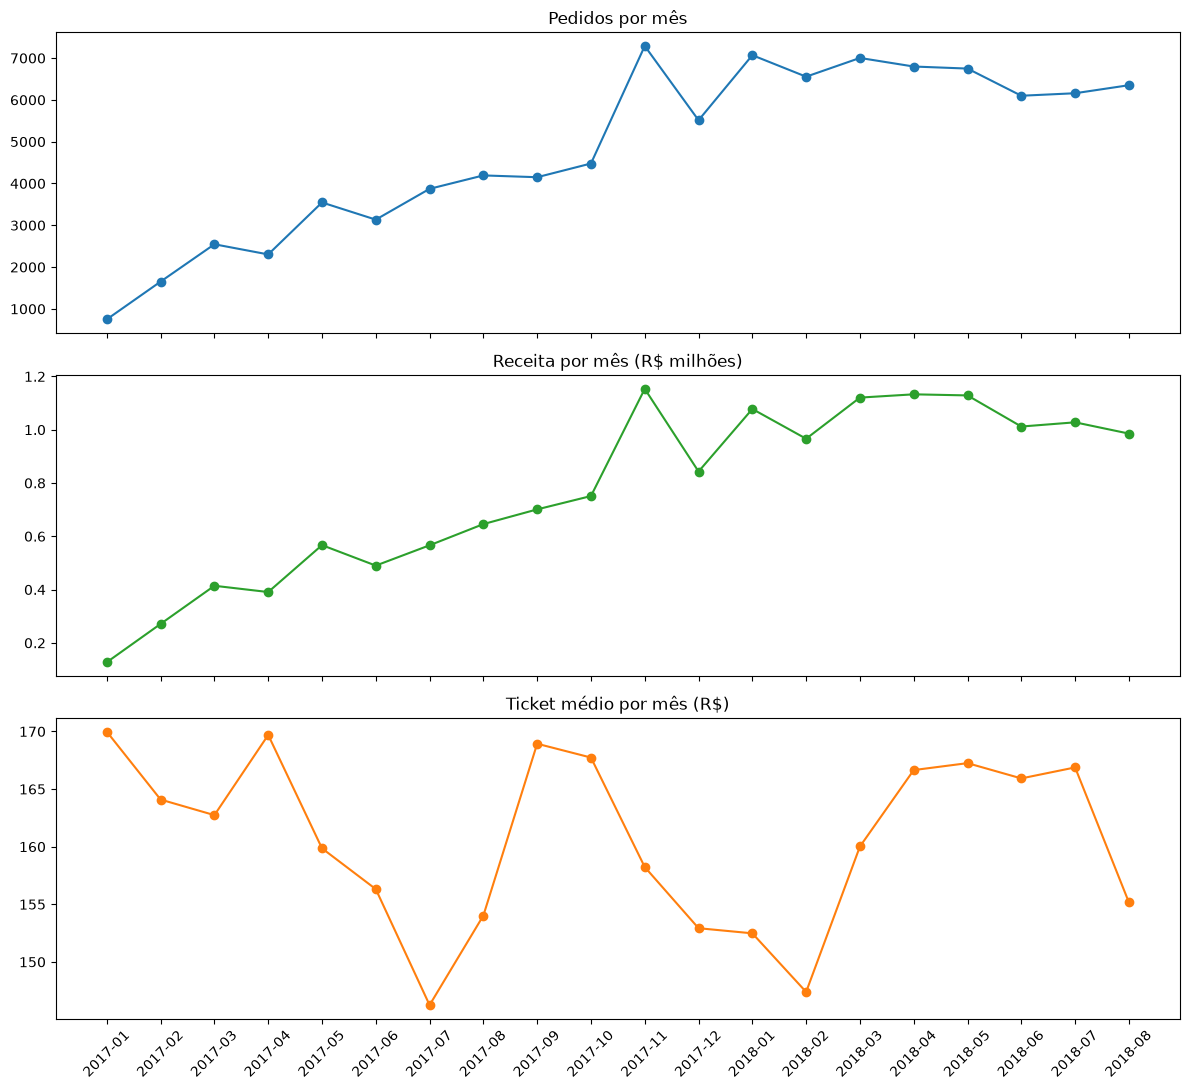

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(12, 11), sharex=True)

axes[0].plot(agg_mensal["purchase_year_month"], agg_mensal["pedidos"], marker="o")
axes[0].set_title("Pedidos por mês")

axes[1].plot(agg_mensal["purchase_year_month"], agg_mensal["receita"] / 1_000_000, marker="o", color="tab:green")
axes[1].set_title("Receita por mês (R$ milhões)")

axes[2].plot(agg_mensal["purchase_year_month"], agg_mensal["ticket_medio"], marker="o", color="tab:orange")
axes[2].set_title("Ticket médio por mês (R$)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Comparação entre os 8 primeiros meses de 2017 e de 2018 (mesmo período nos dois anos, para uma comparação justa).

In [7]:
pedidos_ano = pedidos[pedidos["order_purchase_timestamp"].dt.month <= 8].copy()
pedidos_ano["ano"] = pedidos_ano["order_purchase_timestamp"].dt.year

agg_ano = pedidos_ano.groupby("ano").agg(
    pedidos=("order_id", "count"),
    receita=("order_total", "sum"),
)
agg_ano["ticket_medio"] = agg_ano["receita"] / agg_ano["pedidos"]

agg_ano.loc["crescimento_%"] = (agg_ano.loc[2018] / agg_ano.loc[2017] - 1) * 100
agg_ano

,pedidos,receita,ticket_medio
ano,,,
2017,21998.00000,3.472898e+06,157.873363
2018,52783.00000,8.451585e+06,160.119447
crescimento_%,139.94454,1.433583e+02,1.422712


## 2. Participação por categoria

Receita, pedidos e itens vendidos por categoria, com a participação de cada uma na receita total. A tabela é no nível de item, porque um pedido pode ter produtos de categorias diferentes.

In [8]:
agg_categoria = itens.groupby(["product_category_name", "product_category_name_english"]).agg(
    pedidos=("order_id", "nunique"),
    itens=("order_id", "count"),
    receita=("item_total", "sum"),
).reset_index()

agg_categoria["participacao_receita_pct"] = agg_categoria["receita"] / agg_categoria["receita"].sum() * 100
agg_categoria = agg_categoria.sort_values("receita", ascending=False)

agg_categoria.head(15)

,product_category_name,product_category_name_english,pedidos,itens,receita,participacao_receita_pct
11,BELEZA_SAUDE,HEALTH_BEAUTY,8610,9422,1407759.78,9.157281
66,RELOGIOS_PRESENTES,WATCHES_GIFTS,5491,5855,1261539.41,8.206138
13,CAMA_MESA_BANHO,BED_BATH_TABLE,9267,10945,1224602.68,7.965870
32,ESPORTE_LAZER,SPORTS_LEISURE,7513,8414,1115766.15,7.257903
44,INFORMATICA_ACESSORIOS,COMPUTERS_ACCESSORIES,6518,7632,1031861.93,6.712118
54,MOVEIS_DECORACAO,FURNITURE_DECOR,6258,8095,873430.57,5.681544
73,UTILIDADES_DOMESTICAS,HOUSEWARES,5734,6783,756849.71,4.923202
26,COOL_STUFF,COOL_STUFF,3552,3711,690444.01,4.491242
8,AUTOMOTIVO,AUTO,3802,4132,668103.48,4.345920
40,FERRAMENTAS_JARDIM,GARDEN_TOOLS,3443,4263,565680.49,3.679673


Concentração da receita: quantas categorias respondem pela maior parte do faturamento.

In [9]:
participacao_acumulada = agg_categoria["participacao_receita_pct"].cumsum()

print("Total de categorias:", len(agg_categoria))
print(f"Top 5 categorias: {participacao_acumulada.iloc[4]:.1f}% da receita")
print(f"Top 10 categorias: {participacao_acumulada.iloc[9]:.1f}% da receita")
print("Categorias para chegar a 80% da receita:", (participacao_acumulada < 80).sum() + 1)

Total de categorias: 74
Top 5 categorias: 39.3% da receita
Top 10 categorias: 62.4% da receita
Categorias para chegar a 80% da receita: 18


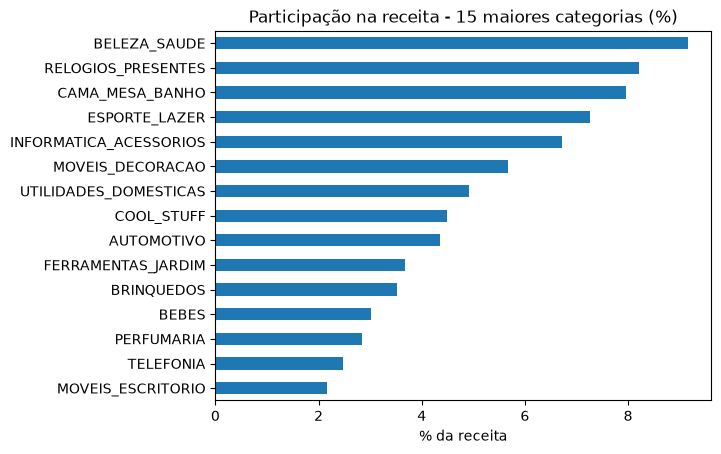

In [10]:
top15_categorias = agg_categoria.head(15).sort_values("participacao_receita_pct")

top15_categorias.plot(kind="barh", x="product_category_name", y="participacao_receita_pct", legend=False)
plt.title("Participação na receita - 15 maiores categorias (%)")
plt.xlabel("% da receita")
plt.ylabel("")
plt.show()

## 3. Participação por UF

Receita, pedidos e ticket médio por estado do cliente, com a participação de cada UF na receita total.

In [11]:
agg_uf = pedidos.groupby("customer_state").agg(
    pedidos=("order_id", "count"),
    receita=("order_total", "sum"),
).reset_index()

agg_uf["ticket_medio"] = agg_uf["receita"] / agg_uf["pedidos"]
agg_uf["participacao_receita_pct"] = agg_uf["receita"] / agg_uf["receita"].sum() * 100
agg_uf = agg_uf.sort_values("receita", ascending=False)

agg_uf

,customer_state,pedidos,receita,ticket_medio,participacao_receita_pct
25,SP,40406,5755999.76,142.454085,37.441975
18,RJ,12310,2046357.64,166.235389,13.311271
10,MG,11319,1813954.27,160.257467,11.799519
22,RS,5328,858574.68,161.143896,5.584908
17,PR,4903,779214.08,158.925980,5.068679
23,SC,3537,592627.06,167.550766,3.854956
4,BA,3253,590816.80,181.622133,3.843181
6,DF,2074,344923.24,166.308216,2.243678
8,GO,1950,333156.23,170.849349,2.167135
7,ES,1992,316666.12,158.968936,2.059869


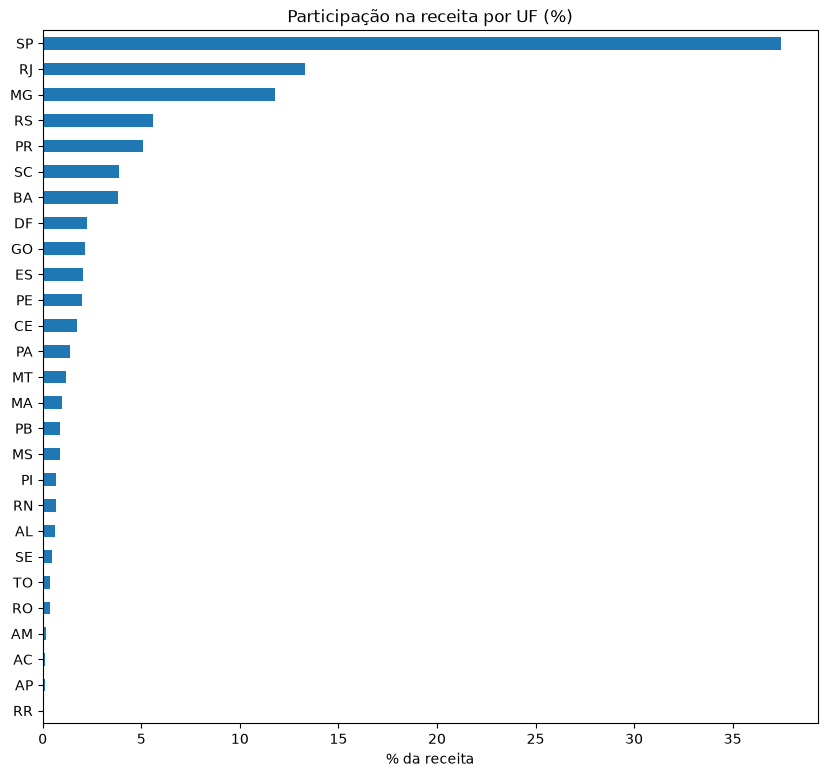

In [12]:
uf_ordenado = agg_uf.sort_values("participacao_receita_pct")

uf_ordenado.plot(kind="barh", x="customer_state", y="participacao_receita_pct", legend=False, figsize=(10, 9))
plt.title("Participação na receita por UF (%)")
plt.xlabel("% da receita")
plt.ylabel("")
plt.show()

Ticket médio por UF. Estados mais distantes do Sudeste tendem a ter ticket maior, em parte pelo frete mais caro.

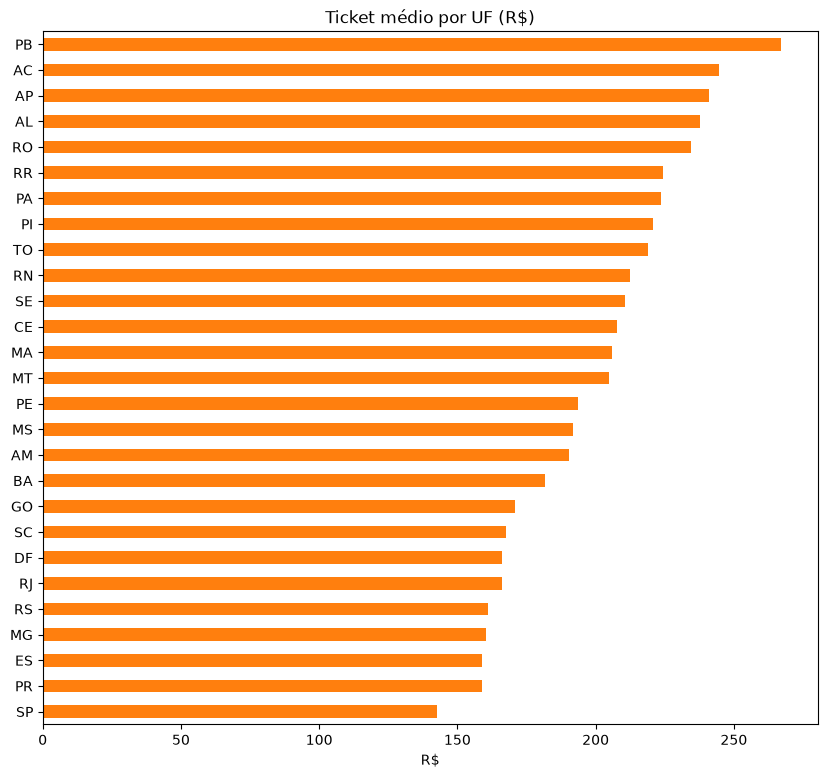

In [13]:
uf_ticket = agg_uf.sort_values("ticket_medio")

uf_ticket.plot(kind="barh", x="customer_state", y="ticket_medio", legend=False, figsize=(10, 9), color="tab:orange")
plt.title("Ticket médio por UF (R$)")
plt.xlabel("R$")
plt.ylabel("")
plt.show()

## 4. Top produtos

Os 10 produtos com maior receita, com a quantidade de itens vendidos e o preço médio.

In [14]:
agg_produto = itens.groupby(["product_id", "product_category_name"]).agg(
    pedidos=("order_id", "nunique"),
    itens=("order_id", "count"),
    receita=("item_total", "sum"),
    preco_medio=("price", "mean"),
).reset_index()

agg_produto["participacao_receita_pct"] = agg_produto["receita"] / agg_produto["receita"].sum() * 100
top_produtos = agg_produto.sort_values("receita", ascending=False).head(10)

top_produtos

,product_id,product_category_name,pedidos,itens,receita,preco_medio,participacao_receita_pct
23451,bb50f2e236e5eea0100680137654686c,BELEZA_SAUDE,186,194,67258.03,327.628866,0.437504
26324,d1c427060a0f73f6b889a5c7c61f2ac4,INFORMATICA_ACESSORIOS,313,332,58957.31,137.411325,0.383509
13691,6cdd53843498f92890544667809f1595,BELEZA_SAUDE,148,153,57933.73,350.668627,0.376851
19212,99a4788cb24856965c36a24e339b6058,CAMA_MESA_BANHO,456,477,49907.50,88.154423,0.324641
7852,3dd2a17168ec895c781a9191c1e95ad7,INFORMATICA_ACESSORIOS,253,272,47876.06,149.936765,0.311427
26881,d6160fb7873f184099d9bc95e30376af,PCS,33,33,47314.18,1392.404545,0.307772
21530,aca2eb7d00ea1a7b8ebd4e68314663af,MOVEIS_DECORACAO,425,520,44197.75,71.354423,0.287500
12025,5f504b3a1c75b73d6151be81eb05bdc9,COOL_STUFF,63,63,41725.81,598.950794,0.271421
4878,25c38557cf793876c5abdd5931f922db,BEBES,38,38,40311.95,1023.876842,0.262224
10575,53b36df67ebb7c41585e8d54d6772e08,RELOGIOS_PRESENTES,304,321,39713.49,116.681090,0.258331


Os 10 produtos mais vendidos em quantidade. Comparar com o ranking por receita mostra a diferença entre produtos de alto giro e produtos de alto valor.

In [15]:
agg_produto.sort_values("itens", ascending=False).head(10)

,product_id,product_category_name,pedidos,itens,receita,preco_medio,participacao_receita_pct
21530,aca2eb7d00ea1a7b8ebd4e68314663af,MOVEIS_DECORACAO,425,520,44197.75,71.354423,0.287500
8399,422879e10f46682990de24d770e7f83d,FERRAMENTAS_JARDIM,352,484,34201.26,54.911612,0.222474
19212,99a4788cb24856965c36a24e339b6058,CAMA_MESA_BANHO,456,477,49907.50,88.154423,0.324641
7182,389d119b48cf3043d311335e499d9c6b,FERRAMENTAS_JARDIM,309,390,28543.65,54.709718,0.185672
6903,368c6c730842d78016ad823897a372db,FERRAMENTAS_JARDIM,291,388,27984.40,54.270103,0.182035
10548,53759a2ecddad2bb87a079a1f1519f73,FERRAMENTAS_JARDIM,287,373,27268.23,54.657373,0.177376
26324,d1c427060a0f73f6b889a5c7c61f2ac4,INFORMATICA_ACESSORIOS,313,332,58957.31,137.411325,0.383509
10575,53b36df67ebb7c41585e8d54d6772e08,RELOGIOS_PRESENTES,304,321,39713.49,116.681090,0.258331
2727,154e7e31ebfa092203795c972e5804a6,BELEZA_SAUDE,262,274,9824.20,22.530146,0.063905
7852,3dd2a17168ec895c781a9191c1e95ad7,INFORMATICA_ACESSORIOS,253,272,47876.06,149.936765,0.311427


## 5. Top sellers

Os 10 vendedores com maior receita. Além do volume, trazemos avaliação média e percentual de atraso, para identificar quem vende muito **e** entrega bem.

A avaliação e o atraso são do pedido; por isso, antes de calcular a média, ficamos com um registro por pedido e seller (um pedido com 3 itens do mesmo seller conta uma vez).

In [16]:
agg_seller = itens.groupby("seller_id").agg(
    pedidos=("order_id", "nunique"),
    itens=("order_id", "count"),
    receita=("item_total", "sum"),
).reset_index()

pedido_seller = itens.drop_duplicates(["order_id", "seller_id"])
qualidade_seller = pedido_seller.groupby("seller_id").agg(
    review_medio=("review_score", "mean"),
    pct_atraso=("is_late", "mean"),
).reset_index()
qualidade_seller["pct_atraso"] = qualidade_seller["pct_atraso"] * 100

agg_seller = agg_seller.merge(qualidade_seller, on="seller_id", how="left")
agg_seller = agg_seller.merge(sellers[["seller_id", "seller_city", "seller_state"]], on="seller_id", how="left")
agg_seller["participacao_receita_pct"] = agg_seller["receita"] / agg_seller["receita"].sum() * 100

top_sellers = agg_seller.sort_values("receita", ascending=False).head(10)
top_sellers

,seller_id,pedidos,itens,receita,review_medio,pct_atraso,seller_city,seller_state,participacao_receita_pct
829,4869f7a5dfa277a7dca6462dcf3b52b2,1124,1148,247007.06,4.150538,10.498221,GUARIBA,SP,1.606746
1472,7c67e1448b00f6e969d365cea6b010ab,973,1355,237806.69,3.495863,9.146968,ITAQUAQUECETUBA,SP,1.546899
853,4a3ca9315b744ce9f8e9374361493884,1772,1949,231220.43,3.853109,9.706546,IBITINGA,SP,1.504057
975,53243585a1d6dc2643021fd1853d8905,348,400,230797.02,4.193642,3.448276,LAURO DE FREITAS,BA,1.501302
2880,fa1c13f2614d7b5c4749cbc52fecda94,578,579,200833.50,4.372822,9.169550,SUMARE,SP,1.306394
2524,da8622b14eb17ae2831f4ac5b9dab84a,1311,1548,184706.78,4.178544,6.636156,PIRACICABA,SP,1.201492
186,1025f0e2d44d7041d6cf58b6550e0bfa,910,1420,171924.96,4.008869,7.912088,SAO PAULO,SP,1.118348
1496,7e93a43ef30c4f03f38b393420bc753a,318,321,170550.00,4.362776,4.716981,BARUERI,SP,1.109404
1442,7a67c85e85bb2ce8582c35f2203ad736,1145,1155,160278.52,4.274846,5.240175,SAO PAULO,SP,1.042589
1747,955fee9216a65b617aa5c0531780ce60,1261,1472,156606.48,4.201117,6.106265,SAO PAULO,SP,1.018703


Concentração da receita entre os sellers.

In [17]:
participacao_seller = agg_seller.sort_values("receita", ascending=False)["participacao_receita_pct"].cumsum()

print("Sellers ativos:", len(agg_seller))
print(f"Top 10 sellers: {participacao_seller.iloc[9]:.1f}% da receita")
print(f"Top 100 sellers: {participacao_seller.iloc[99]:.1f}% da receita")

Sellers ativos: 2945
Top 10 sellers: 13.0% da receita
Top 100 sellers: 44.9% da receita


Média geral para comparação com o top 10.

In [18]:
print(f"Review médio geral: {pedido_seller['review_score'].mean():.2f}")
print(f"% de atraso geral: {pedido_seller['is_late'].mean() * 100:.1f}%")

Review médio geral: 4.14
% de atraso geral: 6.7%


## Conferência

A receita total deve ser a mesma em todas as agregações. Se algum valor diferir, algum filtro ou join está inconsistente.

In [19]:
print(f"Mensal:    R$ {agg_mensal['receita'].sum():,.2f}")
print(f"UF:        R$ {agg_uf['receita'].sum():,.2f}")
print(f"Categoria: R$ {agg_categoria['receita'].sum():,.2f}")
print(f"Produto:   R$ {agg_produto['receita'].sum():,.2f}")
print(f"Seller:    R$ {agg_seller['receita'].sum():,.2f}")

Mensal:    R$ 15,373,120.01
UF:        R$ 15,373,120.01
Categoria: R$ 15,373,120.01
Produto:   R$ 15,373,120.01
Seller:    R$ 15,373,120.01


## Salvar

Grava as agregações em `data/processed/`.

In [20]:
agg_mensal.to_csv("../../data/processed/agg_mensal.csv", index=False)
agg_categoria.to_csv("../../data/processed/agg_categoria.csv", index=False)
agg_uf.to_csv("../../data/processed/agg_uf.csv", index=False)
agg_produto.to_csv("../../data/processed/agg_produto.csv", index=False)
agg_seller.to_csv("../../data/processed/agg_seller.csv", index=False)